In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("/content/agriculture_irrigation.csv")

df.head()

,Timestamp,Farm_ID,Soil_Moisture,Temperature,Humidity,Rainfall,Crop_Stage,Irrigation_Status,Crop_Outcome
0,2026-01-01 06:00:00,F006,44.92,34.03,48.99,0.00,Maturity,No,Healthy
1,2026-01-01 07:00:00,F003,54.82,29.03,71.67,0.00,Vegetative,No,Healthy
2,2026-01-01 07:00:00,F006,41.88,32.63,56.62,0.00,Vegetative,No,Stressed
3,2026-01-01 07:00:00,F009,54.42,31.50,58.61,9.58,Maturity,No,Healthy
4,2026-01-01 07:00:00,F007,29.95,26.23,73.94,0.00,Flowering,Yes,Stressed


In [3]:
df.shape

(5000, 9)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Timestamp          5000 non-null   object 
 1   Farm_ID            5000 non-null   object 
 2   Soil_Moisture      5000 non-null   float64
 3   Temperature        5000 non-null   float64
 4   Humidity           5000 non-null   float64
 5   Rainfall           5000 non-null   float64
 6   Crop_Stage         5000 non-null   object 
 7   Irrigation_Status  5000 non-null   object 
 8   Crop_Outcome       5000 non-null   object 
dtypes: float64(4), object(5)
memory usage: 351.7+ KB


In [5]:
df.columns

Index(['Timestamp', 'Farm_ID', 'Soil_Moisture', 'Temperature', 'Humidity',
       'Rainfall', 'Crop_Stage', 'Irrigation_Status', 'Crop_Outcome'],
      dtype='object')

In [6]:
df.duplicated().sum()

np.int64(0)

In [7]:
df.isnull().sum()

,0
Timestamp,0
Farm_ID,0
Soil_Moisture,0
Temperature,0
Humidity,0
Rainfall,0
Crop_Stage,0
Irrigation_Status,0
Crop_Outcome,0


In [8]:
print("Crop Stages:")
print(df["Crop_Stage"].value_counts())

print("\nIrrigation Status:")
print(df["Irrigation_Status"].value_counts())

print("\nCrop Outcome:")
print(df["Crop_Outcome"].value_counts())

Crop Stages:
Crop_Stage
Vegetative    1747
Flowering     1385
Maturity       980
Seedling       888
Name: count, dtype: int64

Irrigation Status:
Irrigation_Status
No     3286
Yes    1714
Name: count, dtype: int64

Crop Outcome:
Crop_Outcome
Healthy     4418
Stressed     582
Name: count, dtype: int64


In [9]:
df[[
    "Soil_Moisture",
    "Temperature",
    "Humidity",
    "Rainfall"
]].describe()

,Soil_Moisture,Temperature,Humidity,Rainfall
count,5000.000000,5000.000000,5000.000000,5000.000000
mean,46.267688,29.254644,64.754382,2.641890
std,10.244590,4.049099,12.105884,5.608036
min,12.000000,20.000000,35.000000,0.000000
25%,39.355000,26.457500,56.430000,0.000000
50%,45.730000,29.255000,64.805000,0.000000
75%,52.820000,32.010000,73.090000,2.117500
max,85.000000,40.000000,95.000000,40.000000


In [10]:
print("Negative Soil Moisture:", (df["Soil_Moisture"] < 0).sum())
print("Negative Temperature:", (df["Temperature"] < 0).sum())
print("Negative Humidity:", (df["Humidity"] < 0).sum())
print("Negative Rainfall:", (df["Rainfall"] < 0).sum())

Negative Soil Moisture: 0
Negative Temperature: 0
Negative Humidity: 0
Negative Rainfall: 0


In [11]:
df["Timestamp"] = pd.to_datetime(df["Timestamp"])

In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   Timestamp          5000 non-null   datetime64[ns]
 1   Farm_ID            5000 non-null   object        
 2   Soil_Moisture      5000 non-null   float64       
 3   Temperature        5000 non-null   float64       
 4   Humidity           5000 non-null   float64       
 5   Rainfall           5000 non-null   float64       
 6   Crop_Stage         5000 non-null   object        
 7   Irrigation_Status  5000 non-null   object        
 8   Crop_Outcome       5000 non-null   object        
dtypes: datetime64[ns](1), float64(4), object(4)
memory usage: 351.7+ KB


In [13]:
df["Farm_ID"].value_counts().sort_index()

,count
Farm_ID,
F001,519
F002,495
F003,496
F004,477
F005,482
F006,483
F007,515
F008,463
F009,507


In [14]:
df["Crop_Stage"].value_counts()

,count
Crop_Stage,
Vegetative,1747
Flowering,1385
Maturity,980
Seedling,888


In [15]:
df["Irrigation_Status"].value_counts()

,count
Irrigation_Status,
No,3286
Yes,1714


In [16]:
df["Crop_Outcome"].value_counts()

,count
Crop_Outcome,
Healthy,4418
Stressed,582


In [17]:
print("Irrigation Percentage:")
print(df["Irrigation_Status"].value_counts(normalize=True) * 100)

print("\nCrop Outcome Percentage:")
print(df["Crop_Outcome"].value_counts(normalize=True) * 100)

Irrigation Percentage:
Irrigation_Status
No     65.72
Yes    34.28
Name: proportion, dtype: float64

Crop Outcome Percentage:
Crop_Outcome
Healthy     88.36
Stressed    11.64
Name: proportion, dtype: float64


In [18]:
df.describe().T

,count,mean,min,25%,50%,75%,max,std
Timestamp,5000,2026-02-15 12:40:13.440000256,2026-01-01 06:00:00,2026-01-24 12:45:00,2026-02-15 10:00:00,2026-03-10 04:00:00,2026-03-31 20:00:00,NaN
Soil_Moisture,5000.0,46.267688,12.0,39.355,45.73,52.82,85.0,10.24459
Temperature,5000.0,29.254644,20.0,26.4575,29.255,32.01,40.0,4.049099
Humidity,5000.0,64.754382,35.0,56.43,64.805,73.09,95.0,12.105884
Rainfall,5000.0,2.64189,0.0,0.0,0.0,2.1175,40.0,5.608036


In [19]:
df[[
    "Soil_Moisture",
    "Temperature",
    "Humidity",
    "Rainfall"
]].mean()

,0
Soil_Moisture,46.267688
Temperature,29.254644
Humidity,64.754382
Rainfall,2.641890


In [20]:
df[[
    "Soil_Moisture",
    "Temperature",
    "Humidity",
    "Rainfall"
]].median()

df[[
    "Soil_Moisture",
    "Temperature",
    "Humidity",
    "Rainfall"
]].std()

,0
Soil_Moisture,10.244590
Temperature,4.049099
Humidity,12.105884
Rainfall,5.608036


In [21]:
stress_analysis = df.groupby("Crop_Outcome")[
    ["Soil_Moisture", "Temperature", "Humidity", "Rainfall"]
].mean()

stress_analysis

,Soil_Moisture,Temperature,Humidity,Rainfall
Crop_Outcome,,,,
Healthy,46.585197,29.239665,64.702205,2.703164
Stressed,43.857457,29.368351,65.150464,2.176753


In [22]:
stress_analysis.round(2)

,Soil_Moisture,Temperature,Humidity,Rainfall
Crop_Outcome,,,,
Healthy,46.59,29.24,64.70,2.70
Stressed,43.86,29.37,65.15,2.18


In [23]:
df.groupby("Crop_Outcome")["Soil_Moisture"].describe()

,count,mean,std,min,25%,50%,75%,max
Crop_Outcome,,,,,,,,
Healthy,4418.0,46.585197,10.049820,12.00,39.8225,46.015,52.9900,85.00
Stressed,582.0,43.857457,11.340055,15.41,36.6525,43.805,50.9475,81.92


In [24]:
pd.crosstab(
    pd.cut(
        df["Soil_Moisture"],
        bins=[0, 30, 40, 50, 60, 100],
        labels=["<30", "30-40", "40-50", "50-60", "60+"]
    ),
    df["Crop_Outcome"],
    normalize="index"
).round(3) * 100

Crop_Outcome,Healthy,Stressed
Soil_Moisture,,
<30,71.7,28.3
30-40,85.3,14.7
40-50,90.2,9.8
50-60,90.7,9.3
60+,90.4,9.6


In [25]:
def classify_water_stress(moisture):
    if moisture < 30:
        return "High"
    elif moisture < 40:
        return "Moderate"
    else:
        return "Low"

df["Water_Stress_Level"] = df["Soil_Moisture"].apply(classify_water_stress)

df["Water_Stress_Level"].value_counts()

,count
Water_Stress_Level,
Low,3642
Moderate,1114
High,244


In [26]:
pd.crosstab(
    df["Water_Stress_Level"],
    df["Crop_Outcome"],
    normalize="index"
).round(3) * 100

Crop_Outcome,Healthy,Stressed
Water_Stress_Level,,
High,71.7,28.3
Low,90.4,9.6
Moderate,85.4,14.6


In [27]:
unnecessary_irrigation = df[
    (df["Irrigation_Status"] == "Yes") &
    (df["Soil_Moisture"] >= 50)
]

print("Potentially unnecessary irrigation records:",
      len(unnecessary_irrigation))

unnecessary_irrigation.head()

Potentially unnecessary irrigation records: 60


,Timestamp,Farm_ID,Soil_Moisture,Temperature,Humidity,Rainfall,Crop_Stage,Irrigation_Status,Crop_Outcome,Water_Stress_Level
71,2026-01-02 16:00:00,F008,51.01,28.74,79.72,0.0,Flowering,Yes,Healthy,Low
76,2026-01-02 17:00:00,F005,57.58,30.75,63.32,0.0,Vegetative,Yes,Healthy,Low
451,2026-01-09 11:00:00,F003,54.51,27.70,77.37,0.0,Flowering,Yes,Healthy,Low
458,2026-01-09 14:00:00,F003,51.18,36.21,67.47,0.0,Flowering,Yes,Healthy,Low
461,2026-01-09 15:00:00,F001,50.24,29.72,53.02,0.0,Vegetative,Yes,Healthy,Low


In [28]:
rain_irrigation = df[
    (df["Irrigation_Status"] == "Yes") &
    (df["Rainfall"] > 5)
]

print("Irrigation events with significant rainfall:",
      len(rain_irrigation))

Irrigation events with significant rainfall: 52


In [29]:
potential_waste = df[
    (df["Irrigation_Status"] == "Yes") &
    (df["Soil_Moisture"] >= 50) &
    (df["Rainfall"] > 5)
]

print("Potentially unnecessary irrigation after rainfall:",
      len(potential_waste))

Potentially unnecessary irrigation after rainfall: 2


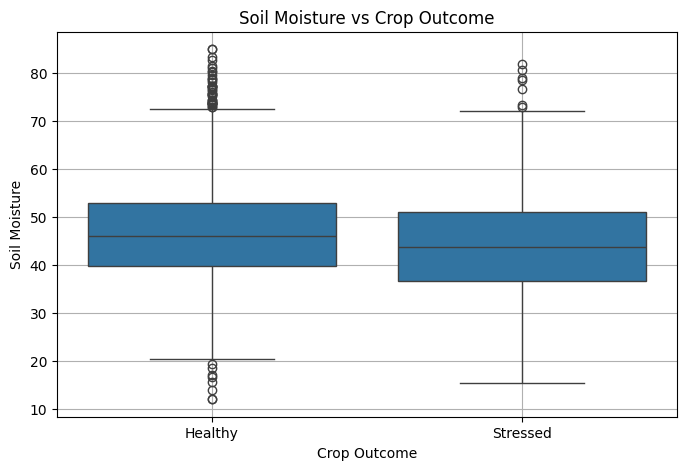

In [30]:
plt.figure(figsize=(8,5))

sns.boxplot(
    data=df,
    x="Crop_Outcome",
    y="Soil_Moisture"
)

plt.title("Soil Moisture vs Crop Outcome")
plt.xlabel("Crop Outcome")
plt.ylabel("Soil Moisture")
plt.grid(True)

plt.show()

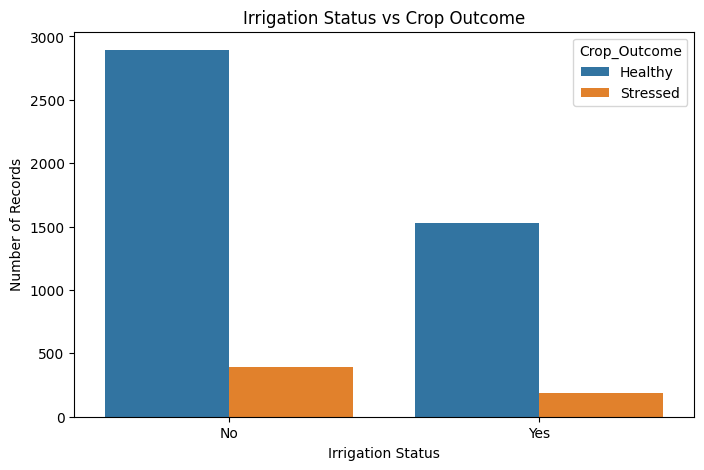

In [31]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    x="Irrigation_Status",
    hue="Crop_Outcome"
)

plt.title("Irrigation Status vs Crop Outcome")
plt.xlabel("Irrigation Status")
plt.ylabel("Number of Records")

plt.show()

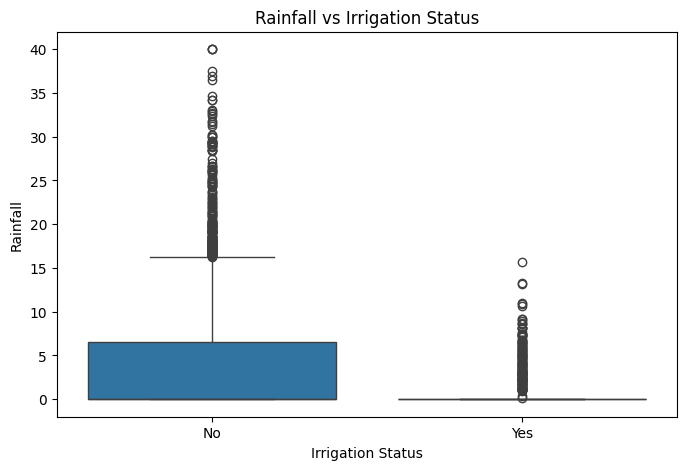

In [32]:
plt.figure(figsize=(8,5))

sns.boxplot(
    data=df,
    x="Irrigation_Status",
    y="Rainfall"
)

plt.title("Rainfall vs Irrigation Status")
plt.xlabel("Irrigation Status")
plt.ylabel("Rainfall")

plt.show()

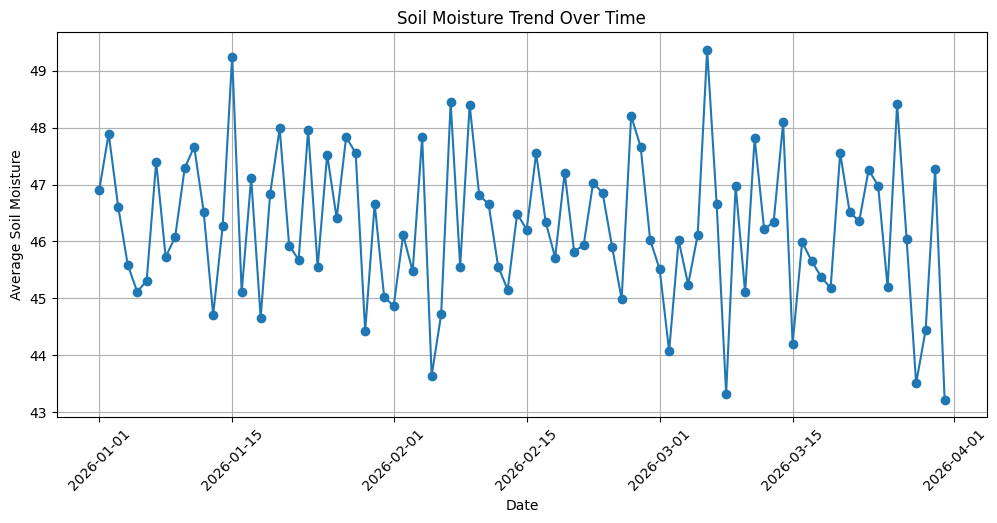

In [33]:
daily_moisture = (
    df.groupby(df["Timestamp"].dt.date)["Soil_Moisture"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(12,5))

plt.plot(
    daily_moisture["Timestamp"],
    daily_moisture["Soil_Moisture"],
    marker="o"
)

plt.title("Soil Moisture Trend Over Time")
plt.xlabel("Date")
plt.ylabel("Average Soil Moisture")
plt.xticks(rotation=45)
plt.grid(True)

plt.show()

In [34]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

# Copy dataset
ml_df = df.copy()

# Encode categorical features
le_crop_stage = LabelEncoder()
le_irrigation = LabelEncoder()
le_outcome = LabelEncoder()

ml_df["Crop_Stage"] = le_crop_stage.fit_transform(ml_df["Crop_Stage"])
ml_df["Irrigation_Status"] = le_irrigation.fit_transform(ml_df["Irrigation_Status"])
ml_df["Crop_Outcome"] = le_outcome.fit_transform(ml_df["Crop_Outcome"])

# Features
X = ml_df[
    [
        "Soil_Moisture",
        "Temperature",
        "Humidity",
        "Rainfall",
        "Crop_Stage",
        "Irrigation_Status"
    ]
]

# Target
y = ml_df["Crop_Outcome"]

print("Features:")
print(X.head())

print("\nTarget:")
print(y.head())

Features:
   Soil_Moisture  Temperature  Humidity  Rainfall  Crop_Stage  \
0          44.92        34.03     48.99      0.00           1   
1          54.82        29.03     71.67      0.00           3   
2          41.88        32.63     56.62      0.00           3   
3          54.42        31.50     58.61      9.58           1   
4          29.95        26.23     73.94      0.00           0   

   Irrigation_Status  
0                  0  
1                  0  
2                  0  
3                  0  
4                  1  

Target:
0    0
1    0
2    1
3    0
4    1
Name: Crop_Outcome, dtype: int64


In [35]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 4000
Testing samples: 1000


In [36]:
from sklearn.tree import DecisionTreeClassifier

# Create Decision Tree model
dt_model = DecisionTreeClassifier(
    criterion="gini",
    max_depth=5,
    random_state=42
)

# Train the model
dt_model.fit(X_train, y_train)

print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


In [37]:
y_pred = dt_model.predict(X_test)

print("Predictions:")
print(y_pred[:20])

Predictions:
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


In [42]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("Decision Tree Model Evaluation")
print("------------------------------")
print("Accuracy :", round(accuracy, 3))
print("Precision:", round(precision, 3))
print("Recall   :", round(recall, 3))
print("F1 Score :", round(f1, 3))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=le_outcome.classes_
))

Decision Tree Model Evaluation
------------------------------
Accuracy : 0.558
Precision: 0.128
Recall   : 0.483
F1 Score : 0.202

Classification Report:
              precision    recall  f1-score   support

     Healthy       0.89      0.57      0.69       884
    Stressed       0.13      0.48      0.20       116

    accuracy                           0.56      1000
   macro avg       0.51      0.53      0.45      1000
weighted avg       0.80      0.56      0.64      1000



In [39]:
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[869  15]
 [115   1]]


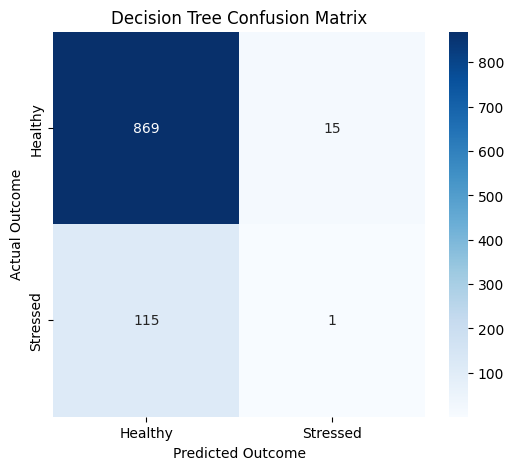

In [40]:
plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=le_outcome.classes_,
    yticklabels=le_outcome.classes_
)

plt.title("Decision Tree Confusion Matrix")
plt.xlabel("Predicted Outcome")
plt.ylabel("Actual Outcome")

plt.show()

In [41]:
dt_model = DecisionTreeClassifier(
    criterion="gini",
    max_depth=5,
    class_weight="balanced",
    random_state=42
)

dt_model.fit(X_train, y_train)

y_pred = dt_model.predict(X_test)

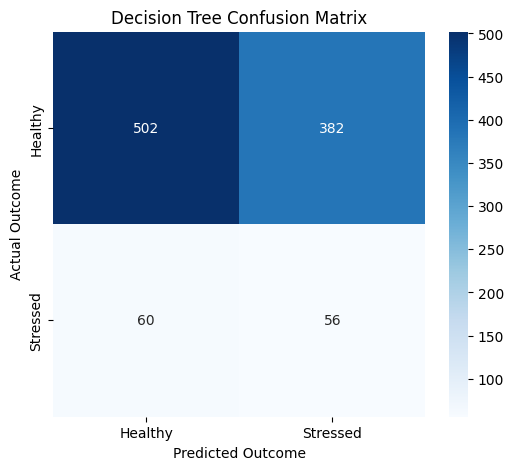

In [43]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=le_outcome.classes_,
    yticklabels=le_outcome.classes_
)

plt.title("Decision Tree Confusion Matrix")
plt.xlabel("Predicted Outcome")
plt.ylabel("Actual Outcome")

plt.show()

In [44]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, accuracy_score

dt_balanced = DecisionTreeClassifier(
    criterion="gini",
    max_depth=5,
    class_weight="balanced",
    random_state=42
)

dt_balanced.fit(X_train, y_train)

y_pred_balanced = dt_balanced.predict(X_test)

print("Balanced Decision Tree Evaluation")
print("---------------------------------")

print("Accuracy:", round(accuracy_score(y_test, y_pred_balanced), 3))

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred_balanced,
        target_names=le_outcome.classes_
    )
)

Balanced Decision Tree Evaluation
---------------------------------
Accuracy: 0.558

Classification Report:
              precision    recall  f1-score   support

     Healthy       0.89      0.57      0.69       884
    Stressed       0.13      0.48      0.20       116

    accuracy                           0.56      1000
   macro avg       0.51      0.53      0.45      1000
weighted avg       0.80      0.56      0.64      1000



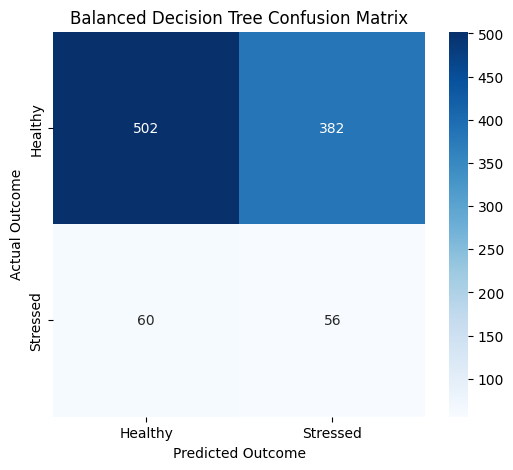

In [45]:
cm = confusion_matrix(y_test, y_pred_balanced)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=le_outcome.classes_,
    yticklabels=le_outcome.classes_
)

plt.title("Balanced Decision Tree Confusion Matrix")
plt.xlabel("Predicted Outcome")
plt.ylabel("Actual Outcome")

plt.show()

In [46]:
feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": dt_balanced.feature_importances_
}).sort_values(
    "Importance",
    ascending=False
)

feature_importance

,Feature,Importance
0,Soil_Moisture,0.518576
5,Irrigation_Status,0.226009
1,Temperature,0.209781
2,Humidity,0.045634
3,Rainfall,0.000000
4,Crop_Stage,0.000000


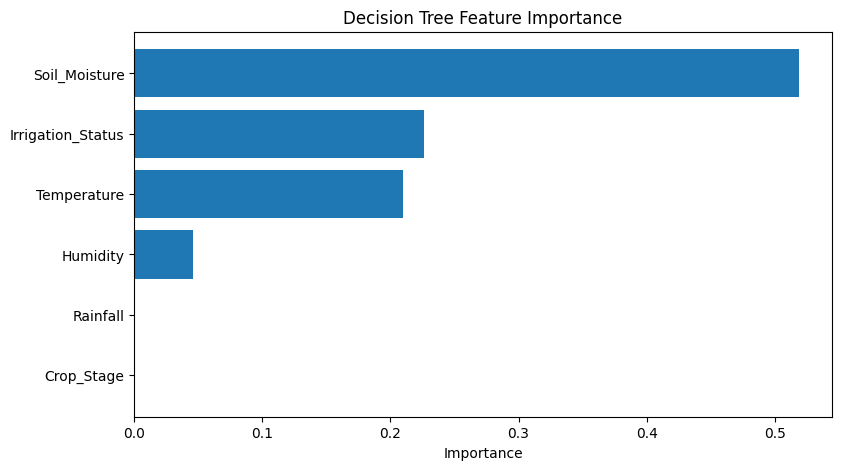

In [47]:
plt.figure(figsize=(9,5))

plt.barh(
    feature_importance["Feature"][::-1],
    feature_importance["Importance"][::-1]
)

plt.title("Decision Tree Feature Importance")
plt.xlabel("Importance")

plt.show()

In [48]:
from sklearn.tree import export_text

rules = export_text(
    dt_balanced,
    feature_names=list(X.columns)
)

print(rules)

|--- Soil_Moisture <= 40.02
|   |--- Soil_Moisture <= 28.91
|   |   |--- Temperature <= 37.65
|   |   |   |--- Irrigation_Status <= 0.50
|   |   |   |   |--- class: 0
|   |   |   |--- Irrigation_Status >  0.50
|   |   |   |   |--- Temperature <= 33.42
|   |   |   |   |   |--- class: 1
|   |   |   |   |--- Temperature >  33.42
|   |   |   |   |   |--- class: 1
|   |   |--- Temperature >  37.65
|   |   |   |--- Soil_Moisture <= 28.00
|   |   |   |   |--- class: 0
|   |   |   |--- Soil_Moisture >  28.00
|   |   |   |   |--- class: 1
|   |--- Soil_Moisture >  28.91
|   |   |--- Irrigation_Status <= 0.50
|   |   |   |--- Soil_Moisture <= 35.93
|   |   |   |   |--- Temperature <= 23.74
|   |   |   |   |   |--- class: 1
|   |   |   |   |--- Temperature >  23.74
|   |   |   |   |   |--- class: 0
|   |   |   |--- Soil_Moisture >  35.93
|   |   |   |   |--- Temperature <= 35.49
|   |   |   |   |   |--- class: 1
|   |   |   |   |--- Temperature >  35.49
|   |   |   |   |   |--- class: 0
|   |   |

In [49]:
import joblib

joblib.dump(dt_balanced, "agriculture_irrigation_decision_tree.pkl")

print("Model saved successfully!")

Model saved successfully!


In [50]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report, accuracy_score

param_grid = {
    "max_depth": [3, 4, 5, 6, 7, 8, 10, None],
    "min_samples_split": [2, 5, 10, 20],
    "min_samples_leaf": [1, 2, 5, 10],
    "class_weight": ["balanced"]
}

grid = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    param_grid,
    scoring="f1_macro",
    cv=5,
    n_jobs=-1
)

grid.fit(X_train, y_train)

print("Best Parameters:")
print(grid.best_params_)

best_dt = grid.best_estimator_

y_pred_best = best_dt.predict(X_test)

print("\nFinal Decision Tree Evaluation")
print("-----------------------------")
print("Accuracy:", round(accuracy_score(y_test, y_pred_best), 3))

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred_best,
        target_names=le_outcome.classes_
    )
)

Best Parameters:
{'class_weight': 'balanced', 'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 5}

Final Decision Tree Evaluation
-----------------------------
Accuracy: 0.759

Classification Report:
              precision    recall  f1-score   support

     Healthy       0.89      0.83      0.86       884
    Stressed       0.13      0.19      0.15       116

    accuracy                           0.76      1000
   macro avg       0.51      0.51      0.51      1000
weighted avg       0.80      0.76      0.78      1000



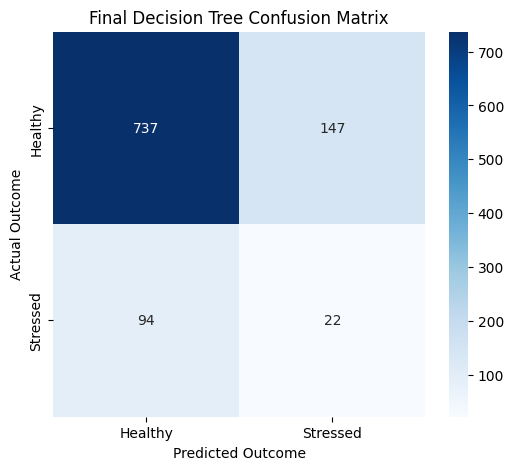

In [51]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred_best)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=le_outcome.classes_,
    yticklabels=le_outcome.classes_
)

plt.title("Final Decision Tree Confusion Matrix")
plt.xlabel("Predicted Outcome")
plt.ylabel("Actual Outcome")

plt.show()

In [52]:
feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": best_dt.feature_importances_
}).sort_values(
    "Importance",
    ascending=False
)

feature_importance

,Feature,Importance
0,Soil_Moisture,0.308977
1,Temperature,0.278719
2,Humidity,0.271470
3,Rainfall,0.060811
4,Crop_Stage,0.047800
5,Irrigation_Status,0.032222


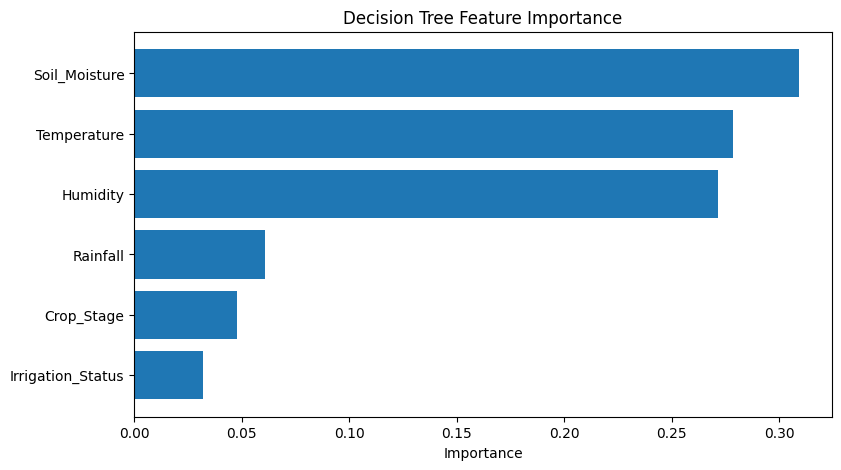

In [53]:
plt.figure(figsize=(9, 5))

plt.barh(
    feature_importance["Feature"][::-1],
    feature_importance["Importance"][::-1]
)

plt.title("Decision Tree Feature Importance")
plt.xlabel("Importance")

plt.show()

In [54]:
action_plan = pd.DataFrame({
    "Condition": [
        "Soil moisture < 30",
        "Soil moisture 30-40",
        "Soil moisture >= 40",
        "Rainfall > 5 and irrigation planned",
        "Soil moisture >= 50 and irrigation planned"
    ],

    "Recommended_Action": [
        "Prioritize irrigation and monitor crop closely",
        "Check crop stage and consider irrigation",
        "Avoid automatic irrigation unless other factors indicate water stress",
        "Reassess irrigation requirement after rainfall",
        "Review irrigation schedule to avoid possible water wastage"
    ]
})

action_plan

,Condition,Recommended_Action
0,Soil moisture < 30,Prioritize irrigation and monitor crop closely
1,Soil moisture 30-40,Check crop stage and consider irrigation
2,Soil moisture >= 40,Avoid automatic irrigation unless other factor...
3,Rainfall > 5 and irrigation planned,Reassess irrigation requirement after rainfall
4,Soil moisture >= 50 and irrigation planned,Review irrigation schedule to avoid possible w...
